Sergei Samoilov

email: ssamoylov@nes.ru

tg: sergei_samoilov244

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

base = Path('.') if Path('NHL-playoffs-2026.xlsx').exists() else Path('FE')
sys.path.insert(0, str(base.resolve()))
from rink import plot_rink

pd.set_option('display.precision', 3)
pd.set_option('display.max_rows', 20)
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams['figure.dpi'] = 110

## 1.

In [2]:
events = pd.read_excel(base / 'NHL-playoffs-2026.xlsx', index_col=0)
events.index.name = None
events.shape

(29710, 38)

In [3]:
events.iloc[:10, [2, 3, 4, 9, 12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


## 2.

In [4]:
games = events.groupby('Game ID').agg({
    'Date': 'first', 'Away Team': 'first', 'Home Team': 'first',
    'Cumulated Away Score': 'max', 'Cumulated Home Score': 'max',
    'Period': 'max'
}).rename(columns={'Cumulated Away Score': 'Away Score',
                   'Cumulated Home Score': 'Home Score'})

def outcome(period):
    overtime = max(int(period) - 3, 0)
    if overtime == 0:
        return 'Final'
    if overtime == 1:
        return 'Final/OT'
    return f'Final/{overtime}OT'

games['Outcome'] = games.pop('Period').map(outcome)
games.columns

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score',
       'Outcome'],
      dtype='object')

In [5]:
games.iloc[-5:, -4:]

,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


## 3.

In [6]:
def gameInfo(gameId):
    game = games.loc[gameId]
    return (f"{game['Home Team']} - {game['Away Team']} "
            f"({game['Home Score']} - {game['Away Score']}, "
            f"{game['Outcome']}, {game['Date']})")

gameInfo(games.index.min())

'Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)'

In [7]:
gameInfo(games.index.max())

'Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)'

## 4.

In [8]:
games['Total Score'] = games['Away Score'] + games['Home Score']
games['Total Score'].describe()

count    82.000
mean      5.927
std       2.260
min       1.000
25%       5.000
50%       6.000
75%       7.000
max      15.000
Name: Total Score, dtype: float64

## 5.

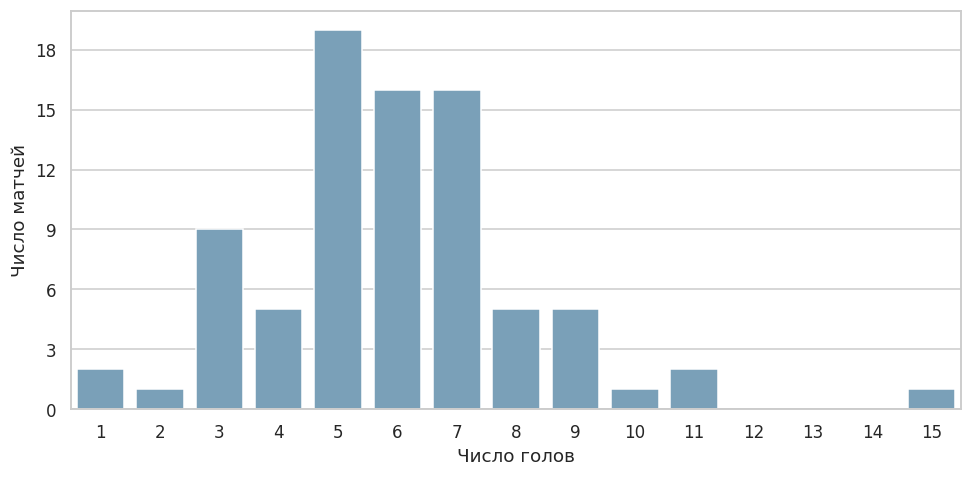

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.countplot(data=games, x='Total Score', order=range(1, 16),
              color='#6fa3c3', ax=ax)
ax.set(xlabel='Число голов', ylabel='Число матчей')
ax.set_yticks(range(0, 19, 3))
plt.tight_layout()
plt.show()

Среднее и медиана забитых за игру шайб 5.92 и 6 соответсвенно. Имеется большой разброс, std – 2.260. Есть выброс в виде 15 шайб за игру. При этом на графике заметно, что данных мало чтобы прикидывать какое-то распределение. Например, дополнительные 10 записей могут существенно его сместить, поэтому какие-то выводы делать по нему тяжело.

## 6.

In [10]:
[gameInfo(i) for i in games.index[games['Total Score'].eq(games['Total Score'].min())]]

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)',
 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

In [11]:
[gameInfo(i) for i in games.index[games['Total Score'].eq(games['Total Score'].max())]]

['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']

## 7.

In [12]:
player_columns = [column for column in events.columns
                  if "Player on the Ice #" in column or column.endswith("'s Goalie")]
player_games = (
    events[['Game ID'] + player_columns]
    .melt(id_vars='Game ID', value_name='Player')
    .dropna(subset=['Player'])[['Game ID', 'Player']]
    .drop_duplicates()
)
player_count = player_games.groupby('Game ID').size().rename('Player Count')
most_players = player_count.loc[player_count.eq(player_count.max())].to_frame()
most_players.insert(0, 'Game Info', most_players.index.map(gameInfo))

most_players

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


в файле задания 41, а не 40. Вероятно, потому что не исключили NaN

## 8.

In [13]:
shot_types = ['shot-on-goal', 'goal', 'missed-shot']
shot_mask = events['Play Type'].isin(shot_types)
shots = events.loc[shot_mask].copy()

home_shot = shots['Team Making the Play'].eq(shots['Home Team'])
home_defends_left = shots["Home Team's Defending Side"].eq('left')
goal_x = np.where(home_shot == home_defends_left, 89, -89)
x = shots['X Coordinate on the Ice Rink']
y = shots['Y Coordinate on the Ice Rink']

distance = np.hypot(x - goal_x, y - y.clip(-3, 3))
events.loc[shot_mask, 'Shot Length'] = distance
shots['Shot Length'] = distance

events.loc[shot_mask, ['Game ID', 'Play Type', 'Shot Length']]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


## 9.

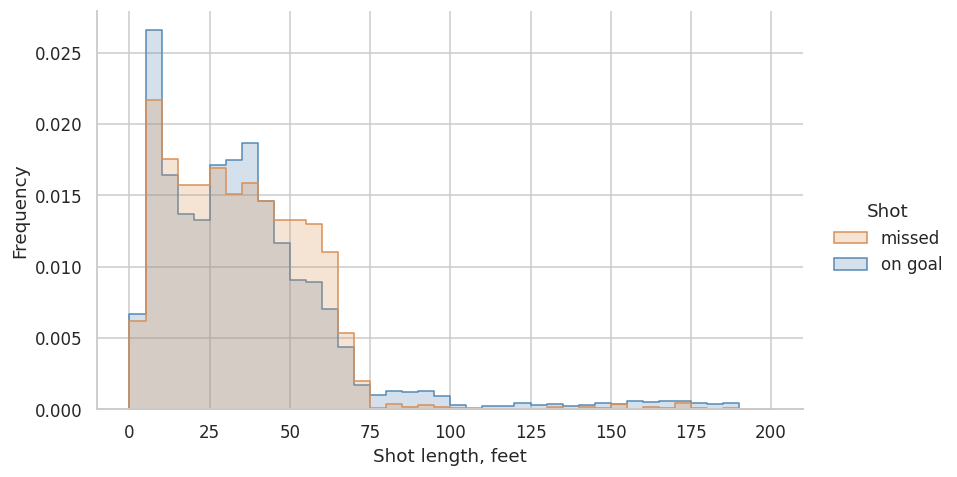

In [14]:
shots['Shot'] = np.where(shots['Play Type'].eq('missed-shot'), 'missed', 'on goal')
g = sns.displot(data=shots, x='Shot Length', hue='Shot',
                hue_order=['missed', 'on goal'], bins=np.arange(0, 201, 5),
                stat='density', common_norm=False, element='step',
                height=4.5, aspect=1.7, palette=['#d99057', '#568ab4'])
g.set_axis_labels('Shot length, feet', 'Frequency')
plt.show()

Возможно броском по воротам регистрировались просто броски со своей половины, которые выполнялись чтобы увести игру на половину соперника. То есть игроки, условно, при расстоянии более 100 не планируют забивать а просто хотят избавиться от шайбы и работать с ней уже у ворот соперника. Длинный хвост тяжело объяснить бросками по пустым воротам. Далее будет видно что из 185 точных со своей половины, только 3 сделаны без вратаря на льду.

In [15]:

shots['Opponent Goalie'] = np.where(
    home_shot, shots["Away Team's Goalie"], shots["Home Team's Goalie"]
)

from_own_half = x * goal_x < 0
pd.crosstab(shots.loc[from_own_half, 'Play Type'],
            shots.loc[from_own_half, 'Opponent Goalie'].notna()).rename(
    columns={False: 'Без вратаря', True: 'Вратарь на льду'}
)


Opponent Goalie,Без вратаря,Вратарь на льду
Play Type,,
goal,3,14
missed-shot,23,4
shot-on-goal,0,168


## 10.

In [16]:
numshots = pd.crosstab([shots['Game ID'], shots['Team Making the Play']], shots['Play Type'])
numshots['Shot'] = numshots['shot-on-goal'] + numshots['goal']
numshots['Share of Shots on Goal'] = numshots['Shot'] / (
    numshots['Shot'] + numshots['missed-shot']
)
numshots['Share of Shots on Goal']

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

In [17]:
numshots['Share of Shots on Goal'].describe()

count    164.000
mean       0.639
std        0.085
min        0.353
25%        0.583
50%        0.639
75%        0.689
max        0.860
Name: Share of Shots on Goal, dtype: float64

В среднем по 164 парам команда–матч в створ попадает около 63.9% бросков. Доля меняется от 35.3% до 86.0%. (Это доля попаданий в створ, а не доля голов!) 

## 11.

In [18]:
avgnumshots = numshots['Share of Shots on Goal'].groupby('Team Making the Play').mean()
avgnumshots.nlargest(5)

Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64

In [19]:
avgnumshots.nsmallest(5)

Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64

Команды сыграли разное число матчей, поэтому надёжность этих средних различается!

Наибольшая средняя доля у Edmonton Oilers 70.6%, а наименьшая у Pittsburgh Penguins 55.4%. Разница около 15.2 процентного пункта. Но только через долю точных бросков нельзя оценить качество команды, важно также число бросков и доля голов среди попаданий в створ.


## 12.

In [20]:
avgshots = numshots.groupby('Team Making the Play')[['Shot', 'goal']].mean()
avgshots = avgshots.rename(columns={'goal': 'Goal'})
avgshots.columns.name = None
avgshots

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


## 13.

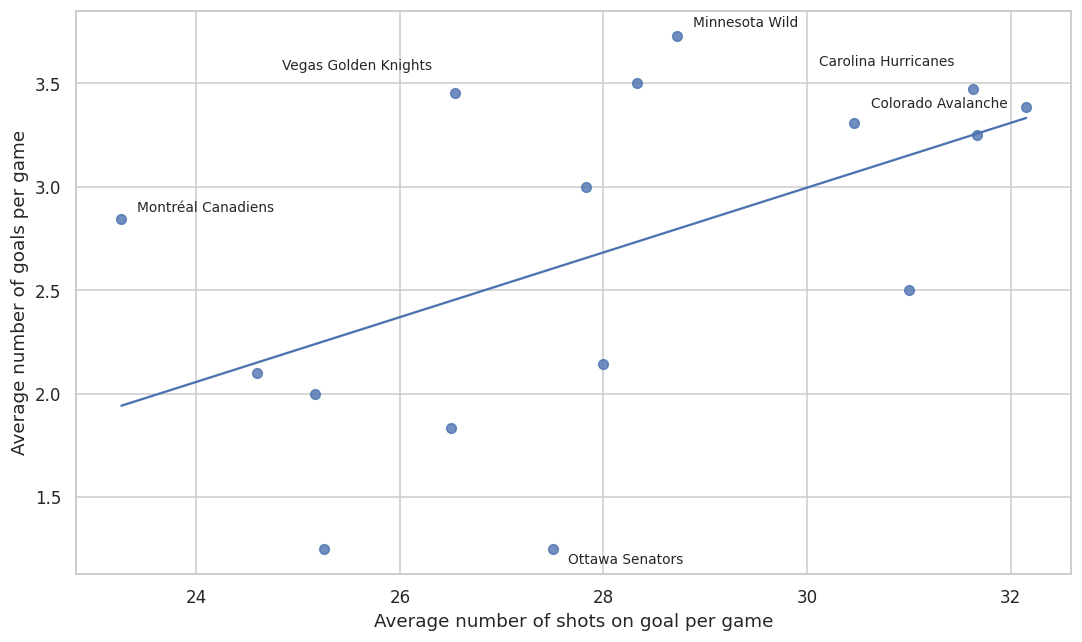

Корреляция: 0.521


In [21]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(data=avgshots, x='Shot', y='Goal', ci=None, ax=ax,
            scatter_kws={'s': 40}, line_kws={'linewidth': 1.5})
labels = {
    'Carolina Hurricanes': (-12, 15),
    'Colorado Avalanche': (-12, 0),
    'Minnesota Wild': (10, 6),
    'Montréal Canadiens': (10, 5),
    'Ottawa Senators': (10, -10),
    'Vegas Golden Knights': (-15, 15)
}
for team, offset in labels.items():
    row = avgshots.loc[team]
    ax.annotate(team, (row['Shot'], row['Goal']), xytext=offset,
                textcoords='offset points', fontsize=9,
                ha='right' if offset[0] < 0 else 'left')
ax.set(xlabel='Average number of shots on goal per game',
       ylabel='Average number of goals per game')
plt.tight_layout()
plt.show()
print('Корреляция:', round(avgshots['Shot'].corr(avgshots['Goal']), 3))


Связь положительная: команды с большим средним числом бросков в створ в целом забивают больше. Однако разброс огромный.
Например, Montréal забивает больше Ottawa при меньшем числе бросков.
Возможно, команды используют принципиально разные тактики, которые предполагют большое или малое количество бросков и малую или большую точность. Кроме того эти тактики может менять одна команды, тогда, что-то предпологать просто по количеству бросков тяжело. 

## 14.

In [22]:
all_shot_types = ['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot']
all_shots = events.loc[events['Play Type'].isin(all_shot_types)].copy()
shot_count = all_shots.groupby('Game ID').size()
idxmax = shot_count.idxmax()
gameInfo(idxmax)

'Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)'

## 15.

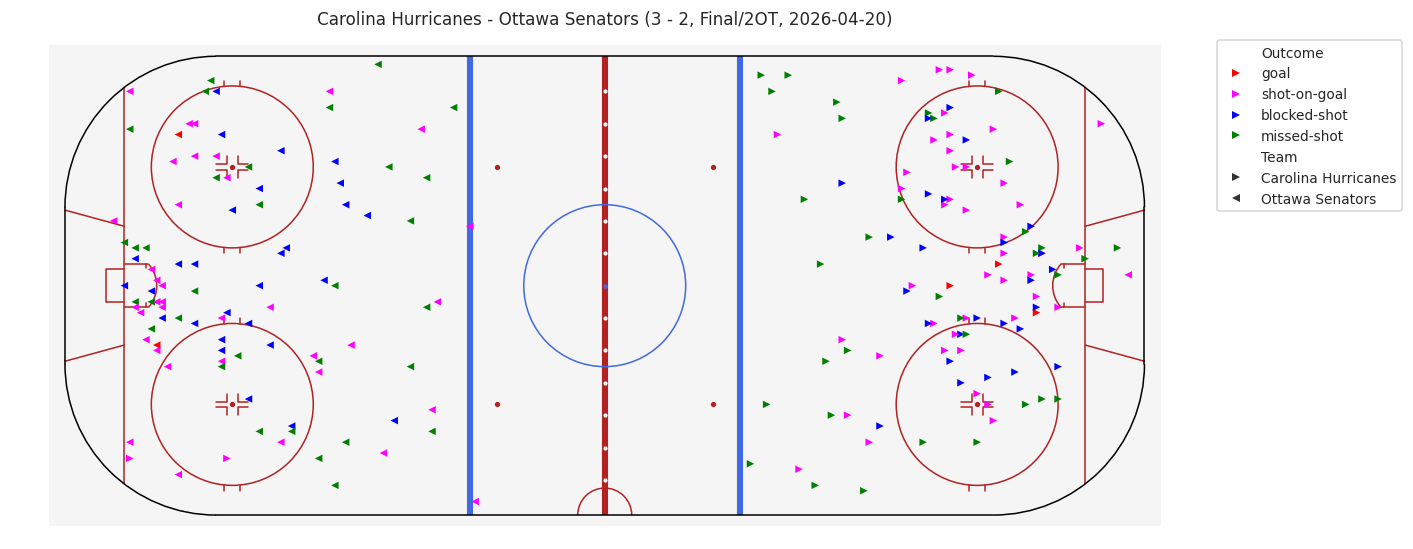

In [23]:
game_shots = all_shots.loc[all_shots['Game ID'].eq(idxmax)].copy()
odd_period = game_shots['Period'].mod(2).eq(1)
coordinates = ['X Coordinate on the Ice Rink', 'Y Coordinate on the Ice Rink']
game_shots.loc[odd_period, coordinates] *= -1
home_team = games.loc[idxmax, 'Home Team']
away_team = games.loc[idxmax, 'Away Team']
plot_data = game_shots.rename(columns={'Play Type': 'Outcome', 'Team Making the Play': 'Team'})

fig, ax = plt.subplots(figsize=(13, 6))
plot_rink()
sns.scatterplot(data=plot_data, x=coordinates[0], y=coordinates[1],
                hue='Outcome', hue_order=all_shot_types,
                palette={'goal': 'red', 'shot-on-goal': 'magenta',
                         'blocked-shot': 'blue', 'missed-shot': 'green'},
                style='Team', style_order=[home_team, away_team],
                markers={home_team: '>', away_team: '<'},
                s=24, linewidth=0, ax=ax)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title(gameInfo(idxmax), fontsize=11)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
plt.tight_layout()
plt.show()

## 16.

In [24]:
goals = events.loc[events['Play Type'].eq('goal')].copy()
goal_count = goals.groupby('Player in the Event #1').size().rename('Goals')
goal_count.index.name = 'Player'
goal_count.sort_index().nlargest(10)

Player
Brett Howden       14
Pavel Dorofeyev    12
Logan Stankoven    11
Mitch Marner       10
Jordan Staal        8
Nikolaj Ehlers      8
Alex Newhook        7
Jackson Blake       7
Mark Stone          7
Matt Boldy          7
Name: Goals, dtype: int64

## 17.

In [25]:
assists = pd.concat([goals['Player in the Event #2'], goals['Player in the Event #3']]).dropna()
assist_count = assists.groupby(assists).size().rename('Assists')
assist_count.index.name = 'Player'
assist_count.sort_index().nlargest(10)

Player
Jack Eichel        20
Mitch Marner       19
Jackson Blake      13
Lane Hutson        13
Martin Necas       12
Nick Suzuki        12
Shea Theodore      12
Taylor Hall        12
Kirill Kaprizov    11
Quinn Hughes       11
Name: Assists, dtype: int64

## 18.

In [26]:
points = goal_count.add(assist_count, fill_value=0).astype(int).rename('Points')
points.sort_index().nlargest(10)

Player
Mitch Marner       29
Jack Eichel        22
Jackson Blake      20
Taylor Hall        19
Brett Howden       18
Nikolaj Ehlers     18
Shea Theodore      18
Lane Hutson        16
Logan Stankoven    16
Nick Suzuki        16
Name: Points, dtype: int64

## 19.

In [27]:
player_game_count = player_games.groupby('Player')['Game ID'].nunique().rename('Games')
player_shot_count = events.loc[
    events['Play Type'].isin(['shot-on-goal', 'goal'])
].groupby('Player in the Event #1').size()
player_shot_count.index.name = 'Player'
player_avg_shots = (player_shot_count.reindex(player_game_count.index, fill_value=0)
                    / player_game_count).rename('Shots per Game')
player_avg_shots.sort_index().nlargest(10)

Player
Jason Robertson     5.000
Dylan Guenther      4.500
Nikita Kucherov     4.429
Matt Boldy          4.364
Quinton Byfield     4.250
Darren Raddysh      4.000
Joel Eriksson Ek    4.000
Alex Laferriere     3.750
David Pastrnak      3.667
Nathan MacKinnon    3.615
Name: Shots per Game, dtype: float64

## 20.

In [28]:
hit_count = events.loc[events['Play Type'].eq('hit')].groupby('Player in the Event #1').size()
hit_count.index.name = 'Player'
player_avg_hits = (hit_count.reindex(player_game_count.index, fill_value=0)
                   / player_game_count).rename('Hits per Game')
player_avg_hits.sort_index().nlargest(10)

Player
Lawson Crouse         6.333
Alex Turcotte         6.000
Alexander Petrovic    6.000
Yakov Trenin          5.667
Dylan Cozens          5.500
Vasily Podkolzin      5.333
Carl Grundstrom       5.000
Ivan Barbashev        5.000
Marcus Foligno        5.000
Owen Tippett          4.833
Name: Hits per Game, dtype: float64

## 21.

In [29]:
# для каждого вратаря учитываем только голы соперника в те моменты когда вратарь указан на льду
goalie_parts = []
for side in ['Away', 'Home']:
    goalie_col = f"{side} Team's Goalie"
    team_col = f'{side} Team'
    part = events[['Game ID', goalie_col, team_col, 'Play Type', 'Team Making the Play']].copy()
    part = part.dropna(subset=[goalie_col])
    part['Goals Against'] = (
        part['Play Type'].eq('goal') & part['Team Making the Play'].ne(part[team_col])
    ).astype(int)
    part = part.rename(columns={goalie_col: 'Goalie', team_col: 'Team'})
    goalie_parts.append(part.groupby(['Game ID', 'Team', 'Goalie'])['Goals Against'].sum())

goalie_games = pd.concat(goalie_parts).sort_index()
zero_goal_games = goalie_games.loc[goalie_games.eq(0)]
clean_goalies = sorted(zero_goal_games.index.get_level_values('Goalie').unique())
clean_goalies

['Andrei Vasilevskiy',
 'Arturs Silovs',
 'Brandon Bussi',
 'Dan Vladar',
 'Frederik Andersen',
 'Jakub Dobes',
 'Joonas Korpisalo',
 'Scott Wedgewood']

## 22


**Как часто команда проигрывает матч, несмотря на преимущество по броскам в створ?**

In [30]:
shot_totals = events.loc[
    events['Play Type'].isin(['shot-on-goal', 'goal'])
].groupby(['Game ID', 'Team Making the Play']).size()

shot_games = games.copy()
for side in ['Home', 'Away']:
    shot_games[f'{side} Shots'] = [
        shot_totals.get((game_id, team), 0)
        for game_id, team in shot_games[f'{side} Team'].items()
    ]

shot_difference = shot_games['Home Shots'] - shot_games['Away Shots']
score_difference = shot_games['Home Score'] - shot_games['Away Score']
unequal_shots = shot_difference.ne(0)
lost_with_advantage = shot_difference * score_difference < 0
loss_share = lost_with_advantage.sum() / unequal_shots.sum()

print(f'Всего матчей: {len(shot_games)}')
print(f'С равным числом бросков в створ: {(~unequal_shots).sum()}')
print(f'Поражений команды с преимуществом по броскам: '
      f'{lost_with_advantage.sum()} из {unequal_shots.sum()}')
print(f'Доля таких поражений: {loss_share:.1%}')

Всего матчей: 82
С равным числом бросков в створ: 4
Поражений команды с преимуществом по броскам: 31 из 78
Доля таких поражений: 39.7%


In [31]:
upsets = shot_games.loc[lost_with_advantage].copy()
upsets['Advantage'] = shot_difference.loc[upsets.index].abs()
records = upsets.loc[upsets['Advantage'].eq(upsets['Advantage'].max())].copy()
loser_is_home = records['Home Score'] < records['Away Score']

record_table = pd.DataFrame(index=records.index)
record_table['Дата'] = records['Date']
record_table['Проигравшая команда'] = np.where(
    loser_is_home, records['Home Team'], records['Away Team']
)
record_table['Соперник'] = np.where(
    loser_is_home, records['Away Team'], records['Home Team']
)
for metric, label in [('Shots', 'Броски в створ'), ('Score', 'Счёт')]:
    loser_value = pd.Series(np.where(
        loser_is_home, records[f'Home {metric}'], records[f'Away {metric}']
    ), index=records.index)
    winner_value = pd.Series(np.where(
        loser_is_home, records[f'Away {metric}'], records[f'Home {metric}']
    ), index=records.index)
    record_table[label] = loser_value.astype(str) + ':' + winner_value.astype(str)
record_table['Преимущество по броскам'] = records['Advantage']
record_table.sort_values('Дата')

,Дата,Проигравшая команда,Соперник,Броски в створ,Счёт,Преимущество по броскам
Game ID,,,,,,
2025030173,2026-04-24,Vegas Golden Knights,Utah Mammoth,32:12,2:4,20
2025030127,2026-05-03,Tampa Bay Lightning,Montréal Canadiens,29:9,1:2,20


Команда с преимуществом по броскам в створ проиграла 31 из 78 матчей, то есть в 39,7% случаев. Еще в четырёх  матчах число бросков было одинаковым.

Максимальное преимущество проигравшей команды 20 бросков. Vegas Golden Knights проиграли Utah Mammoth 2:4 при бросках 32:12, а Tampa Bay Lightning проиграли Montréal Canadiens 1:2 при бросках 29:9.

Таким образом, большее число бросков не гарантирует победу, не смотря на положительную корреляцию.